# Architecture Experiments: Beyond ResNet-18

This notebook compares multiple architectures for single-lead ECG MI detection.
All models are trained with the same improved pipeline (full data, focal loss,
CutMix, cosine LR) from `training_improvements.ipynb`.

### Models:
1. **ResNet-18 + CBAM** — channel + temporal attention (drop-in enhancement)
2. **ResNet-34** — deeper CNN, same family
3. **ResNet-50** — bottleneck blocks, more capacity
4. **Tiny Transformer** — 6.6K params, designed for INT8 deployment
5. **CNN-Transformer** — hybrid CNN-Transformer for single-lead ECG
6. **Mamba (S2M2ECG-style)** — state-space model, linear complexity

### Goal:
Compare AUC, model size, and inference latency across architectures.
The improved ResNet-18 from `training_improvements.ipynb` serves as the baseline.

**Run `training_improvements.ipynb` first** — this notebook depends on its
checkpoints and the full Shaoxing dataset.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import wfdb
import ast
import duckdb
from datetime import datetime
import time

device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

os.makedirs("checkpoints", exist_ok=True)

db = duckdb.connect("experiment_results.duckdb")
db.execute("""
    CREATE TABLE IF NOT EXISTS runs (
        run_id VARCHAR, timestamp TIMESTAMP, stage VARCHAR, dataset VARCHAR,
        epoch INTEGER, train_loss DOUBLE, train_auc DOUBLE,
        val_loss DOUBLE, val_auc DOUBLE, notes VARCHAR
    )
""")
db.execute("""
    CREATE TABLE IF NOT EXISTS arch_comparison (
        run_id VARCHAR, timestamp TIMESTAMP, architecture VARCHAR,
        num_params INTEGER, size_mb DOUBLE,
        ptbxl_val_auc DOUBLE, shaoxing_zeroshot_auc DOUBLE, shaoxing_finetuned_auc DOUBLE,
        inference_ms DOUBLE, notes VARCHAR
    )
""")
RUN_ID = "arch_" + datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"Run ID: {RUN_ID}")

Using device: mps
Run ID: arch_20260403_021733


## 1. Data Loading (same as training_improvements.ipynb)

In [2]:
# --- PTB-XL ---
ptb_path = '../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

def load_ptbxl_data(path):
    df = pd.read_csv(os.path.join(path, 'ptbxl_database.csv'), index_col=0)
    df.scp_codes = df.scp_codes.apply(lambda x: ast.literal_eval(x))
    return df

def aggregate_diagnostic(y_dic, agg_df):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index: tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))

agg_df = pd.read_csv(os.path.join(ptb_path, 'scp_statements.csv'), index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]
df = load_ptbxl_data(ptb_path)
df['diagnostic_class'] = df.scp_codes.apply(aggregate_diagnostic, agg_df=agg_df)
df['MI'] = df.diagnostic_class.apply(lambda x: 1 if 'MI' in x else 0)

train_df = df[df.strat_fold < 9]
val_df = df[df.strat_fold == 9]
test_df = df[df.strat_fold == 10]

print(f"PTB-XL — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} | MI: {df.MI.mean()*100:.2f}%")

# --- Shaoxing (full) ---
shaoxing_path = '../data/a-large-scale-12-lead-electrocardiogram-database-for-arrhythmia-study-1.0.0/'
MI_CODE = '164865005'

class ShaoxingDataset(Dataset):
    def __init__(self, base_path, lead_idx=0, limit=None):
        self.base_path = base_path
        self.lead_idx = lead_idx
        self.records = []
        with open(os.path.join(base_path, 'RECORDS'), 'r') as f:
            subfolders = [line.strip() for line in f if line.strip()]
        for sub in subfolders:
            if limit and len(self.records) >= limit: break
            sub_path = os.path.join(base_path, sub)
            if os.path.exists(sub_path):
                for f in os.listdir(sub_path):
                    if f.endswith('.hea'):
                        self.records.append(os.path.join(sub, f.replace('.hea', '')))
                        if limit and len(self.records) >= limit: break
        self.labels = []
        print(f"Scanning labels for {len(self.records)} Shaoxing records...")
        for rec in tqdm(self.records, desc="Labels"):
            try:
                _, meta = wfdb.rdsamp(os.path.join(base_path, rec))
                dx_list = []
                for c in meta['comments']:
                    if 'Dx:' in c:
                        dx_list = [x.strip() for x in c.split('Dx:')[1].strip().split(',')]
                        break
                self.labels.append(1 if MI_CODE in dx_list else 0)
            except: self.labels.append(0)
        print(f"MI: {sum(self.labels)} ({sum(self.labels)/len(self.labels)*100:.2f}%)")

    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        try:
            signal, _ = wfdb.rdsamp(os.path.join(self.base_path, self.records[idx]))
            s = signal[::5, self.lead_idx].astype(np.float32)
            s = (s - s.mean()) / (s.std() + 1e-8)
            return torch.tensor(s, dtype=torch.float32).unsqueeze(0), torch.tensor(self.labels[idx], dtype=torch.float32)
        except:
            return torch.zeros(1, 1000), torch.tensor(0, dtype=torch.float32)

shaoxing_full = ShaoxingDataset(shaoxing_path)

PTB-XL — Train: 17418 | Val: 2183 | Test: 2198 | MI: 25.09%
Scanning labels for 45152 Shaoxing records...


Labels: 100%|██████████| 45152/45152 [02:01<00:00, 370.31it/s]

MI: 123 (0.27%)


In [3]:
# Augmented PTB-XL dataset
class AugmentedPTBXLDataset(Dataset):
    def __init__(self, df, base_path, lead_idx=0, augment=True):
        self.df = df
        self.base_path = base_path
        self.lead_idx = lead_idx
        self.augment = augment
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        filename = os.path.join(self.base_path, self.df.iloc[idx].filename_lr)
        signal, _ = wfdb.rdsamp(filename)
        s = signal[:, self.lead_idx].astype(np.float32)
        if self.augment:
            if np.random.random() < 0.5: s += np.random.normal(0, 0.02, s.shape).astype(np.float32)
            if np.random.random() < 0.5: s *= np.random.uniform(0.8, 1.2)
            if np.random.random() < 0.3: s = np.roll(s, np.random.randint(-50, 50))
        s = (s - s.mean()) / (s.std() + 1e-8)
        return torch.tensor(s, dtype=torch.float32).unsqueeze(0), torch.tensor(self.df.iloc[idx].MI, dtype=torch.float32)

# Shaoxing stratified split (40/60)
shao_labels = np.array(shaoxing_full.labels)
train_idx, test_idx = train_test_split(np.arange(len(shaoxing_full)), test_size=0.6, stratify=shao_labels, random_state=42)
shao_train = torch.utils.data.Subset(shaoxing_full, train_idx)
shao_test = torch.utils.data.Subset(shaoxing_full, test_idx)
print(f"Shaoxing — Train: {len(shao_train)} | Test: {len(shao_test)}")

Shaoxing — Train: 18060 | Test: 27092


## 2. Shared Training Infrastructure

In [4]:
# Focal loss for class imbalance (better than pos_weight for rare classes)
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        pt = torch.exp(-bce)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt) ** self.gamma * bce).mean()

# CutMix for 1D signals
def cutmix_1d(x, y, alpha=1.0):
    """CutMix adapted for 1D: splice a random time interval from another sample."""
    batch_size = x.size(0)
    seq_len = x.size(2)
    lam = np.random.beta(alpha, alpha)
    cut_len = int(seq_len * (1 - lam))
    cut_start = np.random.randint(0, seq_len - cut_len + 1)
    
    indices = torch.randperm(batch_size).to(x.device)
    x_mixed = x.clone()
    x_mixed[:, :, cut_start:cut_start+cut_len] = x[indices, :, cut_start:cut_start+cut_len]
    
    lam_adjusted = 1 - cut_len / seq_len
    y_mixed = lam_adjusted * y + (1 - lam_adjusted) * y[indices]
    return x_mixed, y_mixed

def evaluate(loader, model, criterion, dev):
    model.eval()
    losses, preds, targets = [], [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            out = model(x).squeeze()
            if out.dim() == 0: out = out.unsqueeze(0)
            losses.append(criterion(out, y).item())
            preds.extend(torch.sigmoid(out).cpu().numpy())
            targets.extend(y.cpu().numpy())
    if len(set(targets)) < 2: return np.mean(losses), 0.5
    return np.mean(losses), roc_auc_score(targets, preds)

def train_epoch(loader, model, criterion, optimizer, dev, use_cutmix=True):
    model.train()
    losses, preds, targets = [], [], []
    for x, y in loader:
        x, y = x.to(dev), y.to(dev)
        if use_cutmix and np.random.random() < 0.5:
            x, y = cutmix_1d(x, y)
        optimizer.zero_grad()
        out = model(x).squeeze()
        if out.dim() == 0: out = out.unsqueeze(0)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        preds.extend(torch.sigmoid(out).detach().cpu().numpy())
        targets.extend(y.detach().cpu().numpy())
    if len(set([int(t > 0.5) for t in targets])) < 2: return np.mean(losses), 0.5
    return np.mean(losses), roc_auc_score([int(t > 0.5) for t in targets], preds)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def benchmark_latency(model, input_shape=(1, 1, 1000), n=100):
    """Measure CPU inference latency."""
    model.eval().cpu()
    dummy = torch.randn(*input_shape)
    for _ in range(10): model(dummy)  # warm-up
    latencies = []
    for _ in range(n):
        start = time.perf_counter()
        with torch.no_grad(): model(dummy)
        latencies.append((time.perf_counter() - start) * 1000)
    model.to(device)
    return np.median(latencies)

print("Training infrastructure ready.")

Training infrastructure ready.


In [5]:
def train_and_evaluate(model, name, pretrain_epochs=15, finetune_epochs=10):
    """Full pipeline: pretrain on PTB-XL, zero-shot eval, fine-tune on Shaoxing."""
    model = model.to(device)
    n_params = count_params(model)
    print(f"\n{'='*60}")
    print(f"  {name} ({n_params:,} params)")
    print(f"{'='*60}")
    
    # --- Pre-train on PTB-XL ---
    batch_size = 64
    train_loader = DataLoader(AugmentedPTBXLDataset(train_df, ptb_path, augment=True), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(AugmentedPTBXLDataset(val_df, ptb_path, augment=False), batch_size=batch_size)
    
    criterion = FocalLoss(alpha=0.25, gamma=2.0)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=pretrain_epochs)
    
    best_val_auc = 0
    ckpt_path = f"../checkpoints/arch_{name.lower().replace(' ', '_')}_pretrained_best.pt"
    
    print(f"\nPre-training ({pretrain_epochs} epochs)...")
    for epoch in range(pretrain_epochs):
        t_loss, t_auc = train_epoch(train_loader, model, criterion, optimizer, device)
        v_loss, v_auc = evaluate(val_loader, model, criterion, device)
        scheduler.step()
        print(f"  Epoch {epoch+1:2d}: T-AUC {t_auc:.3f} | V-AUC {v_auc:.3f}")
        if v_auc > best_val_auc:
            best_val_auc = v_auc
            torch.save({'model_state_dict': model.state_dict()}, ckpt_path)
    
    ptbxl_auc = best_val_auc
    print(f"  Best PTB-XL val AUC: {ptbxl_auc:.4f}")
    
    # Load best pre-trained
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)['model_state_dict'])
    
    # --- Zero-shot Shaoxing ---
    shao_loader = DataLoader(shaoxing_full, batch_size=batch_size)
    _, zeroshot_auc = evaluate(shao_loader, model, criterion, device)
    print(f"  Shaoxing zero-shot AUC: {zeroshot_auc:.4f}")
    
    # --- Fine-tune on Shaoxing ---
    for param in model.parameters(): param.requires_grad = True
    ft_optimizer = optim.Adam(model.parameters(), lr=1e-4)
    ft_scheduler = optim.lr_scheduler.CosineAnnealingLR(ft_optimizer, T_max=finetune_epochs)
    
    shao_train_loader = DataLoader(shao_train, batch_size=batch_size, shuffle=True)
    shao_test_loader = DataLoader(shao_test, batch_size=batch_size)
    
    best_ft_auc = 0
    ft_ckpt_path = f"../checkpoints/arch_{name.lower().replace(' ', '_')}_finetuned_best.pt"
    
    print(f"\nFine-tuning ({finetune_epochs} epochs)...")
    for epoch in range(finetune_epochs):
        t_loss, t_auc = train_epoch(shao_train_loader, model, criterion, ft_optimizer, device)
        v_loss, v_auc = evaluate(shao_test_loader, model, criterion, device)
        ft_scheduler.step()
        print(f"  Epoch {epoch+1:2d}: T-AUC {t_auc:.3f} | V-AUC {v_auc:.3f}")
        if v_auc > best_ft_auc:
            best_ft_auc = v_auc
            torch.save({'model_state_dict': model.state_dict()}, ft_ckpt_path)
    
    print(f"  Best fine-tuned AUC: {best_ft_auc:.4f}")
    
    # --- Latency benchmark ---
    model.load_state_dict(torch.load(ft_ckpt_path, map_location='cpu', weights_only=False)['model_state_dict'])
    latency_ms = benchmark_latency(model)
    
    # --- Model size ---
    torch.save(model.state_dict(), '/tmp/_size_check.pt')
    size_mb = os.path.getsize('/tmp/_size_check.pt') / (1024 * 1024)
    
    # --- Log ---
    db.execute("INSERT INTO arch_comparison VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
        [RUN_ID, datetime.now(), name, n_params, size_mb,
         ptbxl_auc, zeroshot_auc, best_ft_auc, latency_ms, ''])
    
    return {
        'name': name, 'params': n_params, 'size_mb': size_mb,
        'ptbxl_auc': ptbxl_auc, 'zeroshot_auc': zeroshot_auc,
        'finetuned_auc': best_ft_auc, 'latency_ms': latency_ms,
    }

## 3. Architecture Definitions

In [6]:
# --- Shared building blocks ---

def conv3x1(in_planes, out_planes, stride=1):
    return nn.Conv1d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv1d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)

In [7]:
# --- CBAM (Convolutional Block Attention Module) for 1D ---

class ChannelAttention1D(nn.Module):
    """Channel attention: which feature channels matter?"""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.max_pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels, bias=False),
        )
    
    def forward(self, x):
        b, c, _ = x.size()
        avg_out = self.fc(self.avg_pool(x).view(b, c))
        max_out = self.fc(self.max_pool(x).view(b, c))
        attn = torch.sigmoid(avg_out + max_out).unsqueeze(2)
        return x * attn

class TemporalAttention1D(nn.Module):
    """Temporal (spatial) attention: which time steps matter?"""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv1d(2, 1, kernel_size=kernel_size, padding=kernel_size//2, bias=False)
    
    def forward(self, x):
        avg_out = x.mean(dim=1, keepdim=True)
        max_out = x.max(dim=1, keepdim=True)[0]
        attn = torch.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        return x * attn

class CBAM1D(nn.Module):
    """CBAM: channel attention then temporal attention."""
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.channel = ChannelAttention1D(channels, reduction)
        self.temporal = TemporalAttention1D(kernel_size)
    
    def forward(self, x):
        return self.temporal(self.channel(x))

In [8]:
# --- Model 1: ResNet-18 + CBAM ---

class BasicBlockCBAM(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = conv3x1(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x1(planes, planes)
        self.bn2 = nn.BatchNorm1d(planes)
        self.cbam = CBAM1D(planes)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.cbam(out)
        if self.downsample is not None:
            residual = self.downsample(x)
        return self.relu(out + residual)

class ResNet1D(nn.Module):
    """Generic 1D ResNet — supports BasicBlock and BottleneckBlock."""
    def __init__(self, block, layers, num_classes=1):
        self.inplanes = 64
        super().__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(512 * block.expansion, num_classes)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm1d(planes * block.expansion),
            )
        layers = [block(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = self.avgpool(x)
        return self.fc(x.view(x.size(0), -1))

# Plain BasicBlock (no attention)
class BasicBlock1D(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = conv3x1(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x1(planes, planes)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample
    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None: residual = self.downsample(x)
        return self.relu(out + residual)

# Bottleneck for ResNet-50
class Bottleneck1D(nn.Module):
    expansion = 4
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = conv1x1(inplanes, planes)
        self.bn1 = nn.BatchNorm1d(planes)
        self.conv2 = conv3x1(planes, planes, stride)
        self.bn2 = nn.BatchNorm1d(planes)
        self.conv3 = conv1x1(planes, planes * self.expansion)
        self.bn3 = nn.BatchNorm1d(planes * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.downsample is not None: residual = self.downsample(x)
        return self.relu(out + residual)

def resnet18_1d():       return ResNet1D(BasicBlock1D, [2, 2, 2, 2])
def resnet18_cbam_1d():  return ResNet1D(BasicBlockCBAM, [2, 2, 2, 2])
def resnet34_1d():       return ResNet1D(BasicBlock1D, [3, 4, 6, 3])
def resnet50_1d():       return ResNet1D(Bottleneck1D, [3, 4, 6, 3])

print("ResNet variants defined.")
for name, fn in [('ResNet-18', resnet18_1d), ('ResNet-18+CBAM', resnet18_cbam_1d),
                 ('ResNet-34', resnet34_1d), ('ResNet-50', resnet50_1d)]:
    m = fn()
    print(f"  {name}: {count_params(m):,} params")

ResNet variants defined.
  ResNet-18: 3,844,417 params
  ResNet-18+CBAM: 3,931,569 params
  ResNet-34: 7,218,753 params
  ResNet-50: 15,956,289 params


In [9]:
# --- Model 4: Tiny Transformer ---
# Based on: ~6.6K params, 8 attention heads, embedding dim 16
# Convolutional embedding stage -> single transformer encoder block

class ConvEmbedding1D(nn.Module):
    """Convolutional patch embedding for 1D ECG signals."""
    def __init__(self, in_channels=1, embed_dim=16, patch_size=25):
        super().__init__()
        self.proj = nn.Conv1d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.norm = nn.LayerNorm(embed_dim)
    
    def forward(self, x):
        # x: (B, 1, 1000) -> (B, embed_dim, n_patches) -> (B, n_patches, embed_dim)
        x = self.proj(x).transpose(1, 2)
        return self.norm(x)

class TinyTransformer(nn.Module):
    """Minimal transformer for ECG classification.
    ~6.6K params. Designed for INT8 quantization on edge devices."""
    def __init__(self, signal_length=1000, patch_size=25, embed_dim=16,
                 num_heads=8, num_classes=1):
        super().__init__()
        self.n_patches = signal_length // patch_size
        self.embedding = ConvEmbedding1D(1, embed_dim, patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.n_patches + 1, embed_dim))
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=embed_dim * 4, dropout=0.1,
            batch_first=True, activation='gelu'
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.head = nn.Linear(embed_dim, num_classes)
    
    def forward(self, x):
        B = x.size(0)
        x = self.embedding(x)  # (B, n_patches, embed_dim)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1) + self.pos_embed
        x = self.encoder(x)
        return self.head(x[:, 0])  # CLS token

def tiny_transformer(): return TinyTransformer()

m = tiny_transformer()
print(f"Tiny Transformer: {count_params(m):,} params")

Tiny Transformer: 4,417 params


In [10]:
# --- Model 5: CNN-Transformer (Convolution-Attention-Transformer) ---
# Hybrid: CNN feature extractor -> transformer encoder
# Designed for single-lead ECG classification

class CATNet(nn.Module):
    """CNN front-end extracts local features, Transformer captures global dependencies."""
    def __init__(self, num_classes=1, d_model=64, nhead=4, num_encoder_layers=2):
        super().__init__()
        # CNN feature extractor
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(d_model), nn.ReLU(),
        )
        # Positional encoding (learned)
        self.pos_embed = nn.Parameter(torch.zeros(1, 125, d_model))  # 1000 / 8 = 125
        
        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=d_model * 4, dropout=0.1,
            batch_first=True, activation='gelu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)
        
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(d_model, num_classes)
    
    def forward(self, x):
        x = self.cnn(x)  # (B, d_model, seq_len)
        x = x.transpose(1, 2)  # (B, seq_len, d_model)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.transformer(x)
        x = x.transpose(1, 2)  # (B, d_model, seq_len)
        x = self.pool(x).squeeze(-1)
        return self.head(x)

def catnet(): return CATNet()

m = catnet()
print(f"CNN-Transformer: {count_params(m):,} params")

CNN-Transformer: 131,105 params


In [11]:
# --- Model 6: Mamba-style SSM for ECG ---
# Simplified state-space model inspired by S2M2ECG
# Uses 1D convolutions + selective gating (no external mamba dependency)

class SimpleSSMBlock(nn.Module):
    """Simplified selective state-space block.
    Approximates Mamba's selective scan with conv + gating."""
    def __init__(self, d_model, d_state=16, kernel_size=4):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.in_proj = nn.Linear(d_model, d_model * 2)  # gate + value
        self.conv = nn.Conv1d(d_model, d_model, kernel_size=kernel_size,
                             padding=kernel_size-1, groups=d_model)
        self.out_proj = nn.Linear(d_model, d_model)
    
    def forward(self, x):
        # x: (B, seq_len, d_model)
        residual = x
        x = self.norm(x)
        xz = self.in_proj(x)  # (B, seq, 2*d)
        x, z = xz.chunk(2, dim=-1)
        
        # Causal conv
        x = x.transpose(1, 2)  # (B, d, seq)
        x = self.conv(x)[:, :, :residual.size(1)]  # causal: trim future
        x = x.transpose(1, 2)  # (B, seq, d)
        x = F.silu(x)
        
        # Gating
        x = x * F.silu(z)
        x = self.out_proj(x)
        return x + residual

class MambaECG(nn.Module):
    """Mamba-inspired SSM for ECG. Bidirectional processing."""
    def __init__(self, d_model=64, n_layers=4, num_classes=1):
        super().__init__()
        # Convolutional tokenizer
        self.tokenizer = nn.Sequential(
            nn.Conv1d(1, d_model, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(d_model), nn.GELU(),
        )
        
        # Forward and backward SSM blocks
        self.fwd_blocks = nn.ModuleList([SimpleSSMBlock(d_model) for _ in range(n_layers)])
        self.bwd_blocks = nn.ModuleList([SimpleSSMBlock(d_model) for _ in range(n_layers)])
        
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model * 2, num_classes)  # concat fwd + bwd
    
    def forward(self, x):
        x = self.tokenizer(x).transpose(1, 2)  # (B, seq, d)
        
        # Forward pass
        fwd = x
        for block in self.fwd_blocks:
            fwd = block(fwd)
        
        # Backward pass (reverse sequence)
        bwd = x.flip(1)
        for block in self.bwd_blocks:
            bwd = block(bwd)
        bwd = bwd.flip(1)
        
        # Pool and classify
        fwd = self.norm(fwd).mean(dim=1)
        bwd = self.norm(bwd).mean(dim=1)
        return self.head(torch.cat([fwd, bwd], dim=-1))

def mamba_ecg(): return MambaECG()

m = mamba_ecg()
print(f"Mamba-ECG: {count_params(m):,} params")

Mamba-ECG: 104,257 params


## 4. Run All Experiments

In [12]:
models_to_test = [
    ('ResNet-18', resnet18_1d),
    ('ResNet-18+CBAM', resnet18_cbam_1d),
    ('ResNet-34', resnet34_1d),
    ('ResNet-50', resnet50_1d),
    ('Tiny Transformer', tiny_transformer),
    ('CNN-Transformer', catnet),
    ('Mamba-ECG', mamba_ecg),
]

results = []
for name, model_fn in models_to_test:
    result = train_and_evaluate(model_fn(), name)
    results.append(result)
    print(f"\n  => {name}: AUC={result['finetuned_auc']:.4f}, {result['params']:,} params, {result['size_mb']:.1f}MB, {result['latency_ms']:.2f}ms\n")


  ResNet-18 (3,844,417 params)

Pre-training (15 epochs)...
  Epoch  1: T-AUC 0.698 | V-AUC 0.760
  Epoch  2: T-AUC 0.741 | V-AUC 0.780
  Epoch  3: T-AUC 0.755 | V-AUC 0.766
  Epoch  4: T-AUC 0.756 | V-AUC 0.787
  Epoch  5: T-AUC 0.765 | V-AUC 0.781
  Epoch  6: T-AUC 0.773 | V-AUC 0.782
  Epoch  7: T-AUC 0.776 | V-AUC 0.786
  Epoch  8: T-AUC 0.783 | V-AUC 0.786
  Epoch  9: T-AUC 0.788 | V-AUC 0.785
  Epoch 10: T-AUC 0.790 | V-AUC 0.798
  Epoch 11: T-AUC 0.797 | V-AUC 0.794
  Epoch 12: T-AUC 0.802 | V-AUC 0.797
  Epoch 13: T-AUC 0.810 | V-AUC 0.796
  Epoch 14: T-AUC 0.816 | V-AUC 0.798
  Epoch 15: T-AUC 0.820 | V-AUC 0.797
  Best PTB-XL val AUC: 0.7985
  Shaoxing zero-shot AUC: 0.8310

Fine-tuning (10 epochs)...
  Epoch  1: T-AUC 0.726 | V-AUC 0.843
  Epoch  2: T-AUC 0.847 | V-AUC 0.852
  Epoch  3: T-AUC 0.925 | V-AUC 0.827
  Epoch  4: T-AUC 0.955 | V-AUC 0.824
  Epoch  5: T-AUC 0.976 | V-AUC 0.804
  Epoch  6: T-AUC 0.994 | V-AUC 0.725
  Epoch  7: T-AUC 0.998 | V-AUC 0.719
  Epoch  8: 

## 5. Comparison Table & Visualization

  Architecture Comparison: Single-Lead ECG MI Detection
            name   params  size_mb  ptbxl_auc  zeroshot_auc  finetuned_auc  latency_ms
       Mamba-ECG   104257   0.4218     0.7860        0.8302         0.8629     20.1022
       ResNet-18  3844417  14.7396     0.7985        0.8310         0.8517      2.5977
         CNN-Transformer   131105   0.5163     0.7886        0.8190         0.8509      0.9157
       ResNet-34  7218753  27.6691     0.8031        0.8257         0.8484      4.6612
  ResNet-18+CBAM  3931569  15.0826     0.8008        0.8075         0.8437      4.0053
       ResNet-50 15956289  61.1684     0.7946        0.8300         0.8045      7.8335
Tiny Transformer     4417   0.0240     0.7377        0.7331         0.7287      0.3335


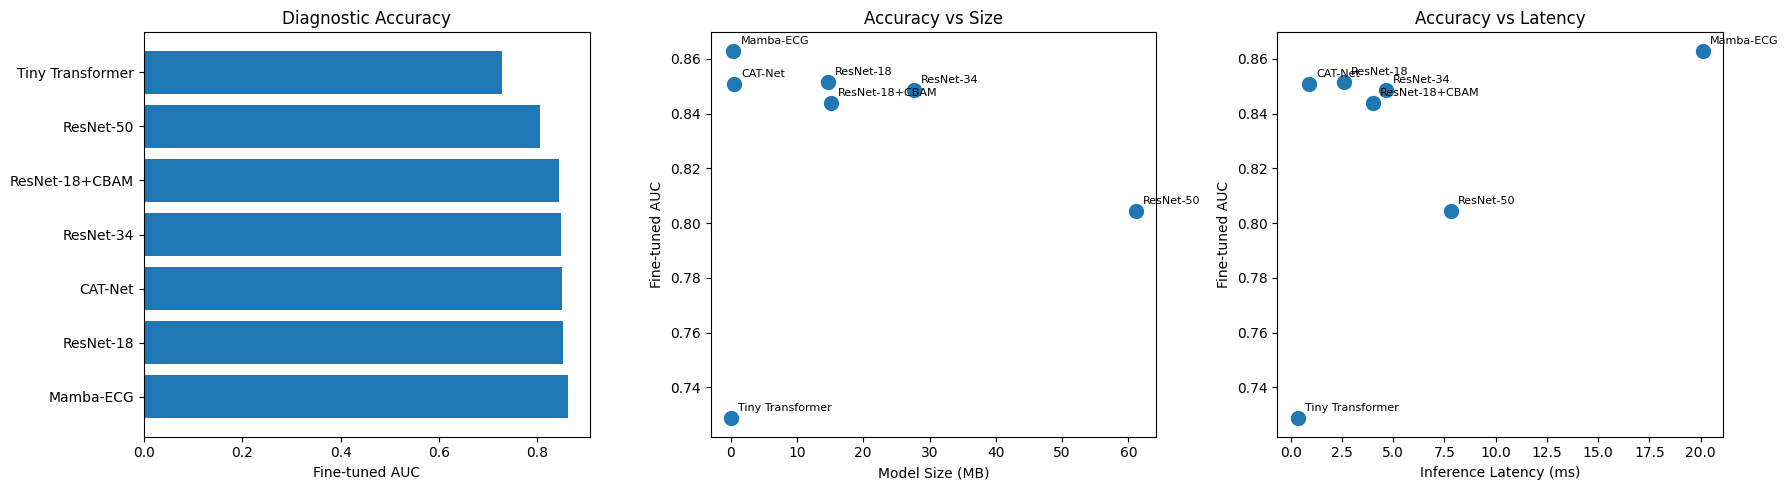

In [13]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('finetuned_auc', ascending=False)

print("=" * 90)
print("  Architecture Comparison: Single-Lead ECG MI Detection")
print("=" * 90)
print(results_df[['name', 'params', 'size_mb', 'ptbxl_auc', 'zeroshot_auc', 'finetuned_auc', 'latency_ms']]
      .to_string(index=False, float_format='%.4f'))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# AUC comparison
x = range(len(results_df))
axes[0].barh(results_df['name'], results_df['finetuned_auc'])
axes[0].set_xlabel('Fine-tuned AUC')
axes[0].set_title('Diagnostic Accuracy')

# Size vs AUC
axes[1].scatter(results_df['size_mb'], results_df['finetuned_auc'], s=100)
for _, row in results_df.iterrows():
    axes[1].annotate(row['name'], (row['size_mb'], row['finetuned_auc']),
                     textcoords='offset points', xytext=(5, 5), fontsize=8)
axes[1].set_xlabel('Model Size (MB)')
axes[1].set_ylabel('Fine-tuned AUC')
axes[1].set_title('Accuracy vs Size')

# Latency vs AUC
axes[2].scatter(results_df['latency_ms'], results_df['finetuned_auc'], s=100)
for _, row in results_df.iterrows():
    axes[2].annotate(row['name'], (row['latency_ms'], row['finetuned_auc']),
                     textcoords='offset points', xytext=(5, 5), fontsize=8)
axes[2].set_xlabel('Inference Latency (ms)')
axes[2].set_ylabel('Fine-tuned AUC')
axes[2].set_title('Accuracy vs Latency')

plt.tight_layout()
plt.show()

db.close()

## 6. On-Device Profiling (Qualcomm AI Hub)

Export top models to ONNX and profile on real mobile hardware.
Compares Samsung Galaxy S24 (flagship) and Xiaomi Redmi Note 10 5G (budget LMIC device).

**Note:** PyTorch's `nn.TransformerEncoder` exports with `SequenceEmpty` and `Loop` ONNX ops
that AI Hub doesn't support. CNN-Transformer uses a manually unrolled transformer to avoid this.


In [15]:
import qai_hub as hub
import torch.nn.functional as F
import onnx
from onnx.external_data_helper import convert_model_from_external_data

client = hub.Client()
print(f"Connected to AI Hub. {len(client.get_devices())} devices available.")

# --- Fixed CNN-Transformer for ONNX export (unrolled transformer, no Loop/SequenceEmpty) ---
class ManualTransformerBlock(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, dim_feedforward), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model), nn.Dropout(dropout),
        )
    def forward(self, x):
        x2 = self.norm1(x)
        x = x + self.attn(x2, x2, x2, need_weights=False)[0]
        return x + self.ff(self.norm2(x))

class CATNetExport(nn.Module):
    def __init__(self, num_classes=1, d_model=64, nhead=4):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(d_model), nn.ReLU(),
        )
        self.pos_embed = nn.Parameter(torch.zeros(1, 125, d_model))
        self.block1 = ManualTransformerBlock(d_model, nhead, d_model * 4)
        self.block2 = ManualTransformerBlock(d_model, nhead, d_model * 4)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(d_model, num_classes)
    def forward(self, x):
        x = self.cnn(x).transpose(1, 2)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.block2(self.block1(x))
        return self.head(self.pool(x.transpose(1, 2)).squeeze(-1))


Connected to AI Hub. 81 devices available.


In [16]:
# Export top 3 models to ONNX for AI Hub profiling
os.makedirs("../models", exist_ok=True)

def export_onnx(model, path):
    model.eval().cpu()
    torch.onnx.export(model, torch.randn(1, 1, 1000), path,
        input_names=["ecg_lead"], output_names=["mi_logit"], opset_version=18)
    onnx_model = onnx.load(path, load_external_data=True)
    convert_model_from_external_data(onnx_model)
    onnx.save(onnx_model, path)
    if os.path.exists(path + ".data"): os.remove(path + ".data")
    size = os.path.getsize(path) / (1024*1024)
    print(f"  {path}: {size:.2f} MB")
    return path

exports = {}

# ResNet-18
m = resnet18_1d()
ckpt = torch.load("../checkpoints/arch_resnet-18_finetuned_best.pt", map_location="cpu", weights_only=False)
m.load_state_dict(ckpt['model_state_dict'])
exports['ResNet-18'] = export_onnx(m, "../models/arch_resnet18.onnx")

# Mamba-ECG
m = mamba_ecg()
ckpt = torch.load("../checkpoints/arch_mamba-ecg_finetuned_best.pt", map_location="cpu", weights_only=False)
m.load_state_dict(ckpt['model_state_dict'])
exports['Mamba-ECG'] = export_onnx(m, "../models/arch_mamba.onnx")

# CNN-Transformer (fixed export version)
catnet_export = CATNetExport()
ckpt = torch.load("../checkpoints/arch_cat-net_finetuned_best.pt", map_location="cpu", weights_only=False)
# Remap weights from original CNN-Transformer to export version
old_sd = ckpt['model_state_dict']
new_sd = catnet_export.state_dict()
for old_key in old_sd:
    new_key = old_key.replace('transformer.layers.0.', 'block1.').replace('transformer.layers.1.', 'block2.')
    new_key = new_key.replace('.self_attn.', '.attn.').replace('.linear1.', '.ff.0.').replace('.linear2.', '.ff.3.')
    if new_key in new_sd and old_sd[old_key].shape == new_sd[new_key].shape:
        new_sd[new_key] = old_sd[old_key]
catnet_export.load_state_dict(new_sd)
exports['CNN-Transformer'] = export_onnx(catnet_export, "../models/arch_catnet.onnx")

print(f"\nExported {len(exports)} models.")


[torch.onnx] Obtain model graph for `ResNet1D([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet1D([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/Users/gabrielbutler/.pyenv/versions/3.11.9/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Applied 40 of general pattern rewrite rules.
  ../models/arch_resnet18.onnx: 14.74 MB
[torch.onnx] Obtain model graph for `MambaECG([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MambaECG([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/Users/gabrielbutler/.pyenv/versions/3.11.9/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Applied 2 of general pattern rewrite rules.
  ../models/arch_mamba.onnx: 0.55 MB
[torch.onnx] Obtain model graph for `CATNetExport([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CATNetExport([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Applied 8 of general pattern rewrite rules.
  ../models/arch_catnet.onnx: 0.63 MB

Exported 3 models.


/Users/gabrielbutler/.pyenv/versions/3.11.9/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


In [17]:
# Compile and profile all models on both devices
import json as _json

devices_cfg = {
    "s24": {
        "device": hub.Device("Samsung Galaxy S24 (Family)"),
        "label": "Samsung Galaxy S24 (Snapdragon 8 Gen 3)",
        "runtime": "--target_runtime qnn_context_binary",
    },
    "redmi": {
        "device": hub.Device("Xiaomi Redmi Note 10 5G"),
        "label": "Xiaomi Redmi Note 10 5G (Snapdragon 678)",
        "runtime": None,
    },
}

PROFILE_CACHE = "../cache/arch_profile_results.json"

if os.path.exists(PROFILE_CACHE):
    with open(PROFILE_CACHE) as f:
        profile_results = _json.load(f)
    print("Loaded cached profile results.")
else:
    profile_results = {}

    for model_name, onnx_path in exports.items():
        profile_results[model_name] = {}
        for dev_key, cfg in devices_cfg.items():
            print(f"\n--- {model_name} on {cfg['label']} ---")
            try:
                kwargs = dict(model=onnx_path, device=cfg["device"], name=f"arch_{model_name}_{dev_key}")
                if cfg["runtime"]: kwargs["options"] = cfg["runtime"]
                
                compile_job = client.submit_compile_job(**kwargs)
                print(f"  Compile submitted...")
                compile_job.wait()
                status = compile_job.get_status()
                if "FAILED" in str(status.code):
                    print(f"  COMPILE FAILED: {status.message[:120]}")
                    profile_results[model_name][dev_key] = {"status": "compile_failed", "error": status.message[:200]}
                    continue
                
                profile_job = client.submit_profile_job(
                    model=compile_job.get_target_model(), device=cfg["device"],
                    name=f"arch_{model_name}_{dev_key}_profile")
                print(f"  Profile submitted...")
                profile_job.wait()
                pstatus = profile_job.get_status()
                if "FAILED" in str(pstatus.code):
                    print(f"  PROFILE FAILED: {pstatus.message[:120]}")
                    profile_results[model_name][dev_key] = {"status": "profile_failed", "error": pstatus.message[:200]}
                    continue
                
                data = profile_job.download_profile()
                summary = data.get("execution_summary", data) if isinstance(data, dict) else {}
                result = {
                    "status": "success",
                    "inference_us": summary.get("estimated_inference_time"),
                    "peak_memory_bytes": summary.get("estimated_inference_peak_memory"),
                }
                profile_results[model_name][dev_key] = result
                print(f"  inference: {result['inference_us']} us, memory: {result['peak_memory_bytes']} bytes")
            except Exception as e:
                print(f"  ERROR: {e}")
                profile_results[model_name][dev_key] = {"status": "error", "error": str(e)[:200]}

    with open(PROFILE_CACHE, 'w') as f:
        _json.dump(profile_results, f, indent=2)
    print(f"\nSaved results to {PROFILE_CACHE}")



--- ResNet-18 on Samsung Galaxy S24 (Snapdragon 8 Gen 3) ---
Uploading arch_resnet18.onnx


100%|██████████| 14.7M/14.7M [00:04<00:00, 3.24MB/s]


Scheduled compile job (jgo1m1045) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jgo1m1045/

  Compile submitted...
Waiting for compile job (jgo1m1045) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
Scheduled profile job (jper2r17g) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jper2r17g/

  Profile submitted...
Waiting for profile job (jper2r17g) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
  inference: 328 us, memory: 102506496 bytes

--- ResNet-18 on Xiaomi Redmi Note 10 5G (Snapdragon 678) ---
Uploading arch_resnet18.onnx


100%|██████████| 14.7M/14.7M [00:04<00:00, 3.77MB/s]


Scheduled compile job (jg93831qg) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jg93831qg/

  Compile submitted...
Waiting for compile job (jg93831qg) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
Scheduled profile job (jp1d3dlkp) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jp1d3dlkp/

  Profile submitted...
Waiting for profile job (jp1d3dlkp) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
  inference: 4244 us, memory: 98627584 bytes

--- Mamba-ECG on Samsung Galaxy S24 (Snapdragon 8 Gen 3) ---
Uploading arch_mamba.onnx


100%|██████████| 561k/561k [00:00<00:00, 692kB/s]  


... (3 outputs left out)

100%|██████████| 649k/649k [00:00<00:00, 799kB/s]  


Scheduled compile job (jgl070reg) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jgl070reg/

  Compile submitted...
Waiting for compile job (jgl070reg) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
Scheduled profile job (j563v3lv5) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/j563v3lv5/

  Profile submitted...
Waiting for profile job (j563v3lv5) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
  inference: 161 us, memory: 100630528 bytes

--- CNN-Transformer on Xiaomi Redmi Note 10 5G (Snapdragon 678) ---
Uploading arch_catnet.onnx


100%|██████████| 649k/649k [00:00<00:00, 898kB/s]  


Scheduled compile job (jgj01047p) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jgj01047p/

  Compile submitted...
Waiting for compile job (jgj01047p) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
Scheduled profile job (jper2r37g) successfully. To see the status and results:
    https://workbench.aihub.qualcomm.com/jobs/jper2r37g/

  Profile submitted...
Waiting for profile job (jper2r37g) completion. Type Ctrl+C to stop waiting at any time.
    ✅ SUCCESS                          
  inference: 1884 us, memory: 77836288 bytes

Saved results to ../cache/arch_profile_results.json


In [18]:
# Display on-device profiling results
print("=" * 80)
print("  On-Device Profiling: Qualcomm AI Hub")
print("=" * 80)
print(f"{'Model':<20s} {'S24 (us)':>10s} {'S24 Mem':>10s} {'Redmi (us)':>12s} {'Redmi Mem':>10s}")
print("-" * 80)

for model_name in exports:
    s24 = profile_results.get(model_name, {}).get("s24", {})
    redmi = profile_results.get(model_name, {}).get("redmi", {})
    
    s24_t = str(s24.get("inference_us", "N/A")) if s24.get("status") == "success" else "FAILED"
    s24_m = f"{s24.get('peak_memory_bytes', 0)/(1024*1024):.0f} MB" if s24.get("status") == "success" else "N/A"
    r_t = str(redmi.get("inference_us", "N/A")) if redmi.get("status") == "success" else "FAILED"
    r_m = f"{redmi.get('peak_memory_bytes', 0)/(1024*1024):.0f} MB" if redmi.get("status") == "success" else "N/A"
    
    print(f"{model_name:<20s} {s24_t:>10s} {s24_m:>10s} {r_t:>12s} {r_m:>10s}")
    
    # Print failure reason if any
    for dev_key, dev_name in [("s24", "S24"), ("redmi", "Redmi")]:
        data = profile_results.get(model_name, {}).get(dev_key, {})
        if data.get("status") not in ("success", None) and data.get("error"):
            print(f"  ^ {dev_name}: {data['error'][:100]}")


  On-Device Profiling: Qualcomm AI Hub
Model                  S24 (us)    S24 Mem   Redmi (us)  Redmi Mem
--------------------------------------------------------------------------------
ResNet-18                   328      98 MB         4244      94 MB
Mamba-ECG                   262      98 MB         3344      92 MB
CNN-Transformer                     161      96 MB         1884      74 MB
